# Case 5: Early glaucoma (pre-perimetric), future capability illustration

*Hands-On Electroretinography in the Age of AI*, Chapter 19, §19.5.

Mr. D. is in the 60y and older age stratum. His OCT shows RNFL thinning, and the ERG tests whether a functional correlate is present. The photopic negative response (PhNR) of the LA 3.0 ERG reflects retinal ganglion cell function, but it has no published reference limits yet. This notebook assigns the zones of Table 19.6 with the pipeline code and checks zones and printed limits against the book. It then shows the AMBER zone the PhNR would receive as a target capability, and the Level 1 SHAP contributions of Figure 19.4.

The values are constructed for teaching; they are not patient data. Limits: Baker et al. (2025), silver thread, 60y and older.

**Setup.** In Google Colab, the first cell clones the repository. Elsewhere, run the notebook from the repository.

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('/content/ERG-Analysis-API'):
    !git clone -q https://github.com/AI-Fairness-com/ERG-Analysis-API.git /content/ERG-Analysis-API
sys.path.insert(0, '/content/ERG-Analysis-API/examples')
sys.path.insert(0, os.path.abspath('examples') if os.path.isdir('examples') else os.getcwd())
from case_helpers import zone_table, check, REPORT

**Table 19.6 values.** The PhNR row is checked as *not zoned*, which is what the pipeline does today; its target zone is shown in the next step.

In [2]:
ROWS = [
    ('DA 3.0',  'a-wave amplitude',      112,  'GREEN', (80, 220)),
    ('DA 3.0',  'a-wave implicit time',  16.2, 'GREEN', (14.5, 18)),
    ('DA 3.0',  'b-wave amplitude',      215,  'GREEN', (162, 407)),
    ('DA 3.0',  'b-wave implicit time',  51.4, 'GREEN', (46.5, 58)),
    ('LA 3.0',  'a-wave amplitude',      21,   'GREEN', (12, 35)),
    ('LA 3.0',  'a-wave implicit time',  14.3, 'GREEN', (13, 15.5)),
    ('LA 3.0',  'b-wave amplitude',      90,   'GREEN', (49, 153)),
    ('LA 3.0',  'b-wave implicit time',  28.1, 'GREEN', (27.5, 32.5)),
    ('LA 30 Hz', 'flicker amplitude',    58,   'GREEN', (38, 116)),
    ('LA 30 Hz', 'flicker implicit time', 28.4, 'GREEN', (24.5, 30.5)),
    ('LA 3.0',  'PhNR amplitude',        9.8,  'Not zoned'),
    ('LA 3.0',  'OP2 amplitude',         7.2,  'Not zoned'),
    ('LA 3.0',  'OP2 implicit time',     21.1, 'Not zoned'),
    ('LA 3.0',  'OP power ratio',        0.44, 'Not zoned'),
]

**Zones.** Every zoned parameter is GREEN, so the composite Traffic Light is GREEN: the standard ERG alone would not raise this case.

In [3]:
table, signal = zone_table(ROWS, age=65)
print(table.drop(columns='Match').to_string(index=False))
print('\nComposite Traffic Light:', signal)
check(table)

Protocol             Parameter  Value                            Limits Zone (code) Zone (book)
  DA 3.0      a-wave amplitude 112.00     80 to 220 (L_lo 72, U_hi 234)       GREEN       GREEN
  DA 3.0  a-wave implicit time  16.20   14.5 to 18 (L_lo 14, U_hi 18.5)       GREEN       GREEN
  DA 3.0      b-wave amplitude 215.00   162 to 407 (L_lo 151, U_hi 458)       GREEN       GREEN
  DA 3.0  b-wave implicit time  51.40   46.5 to 58 (L_lo 45.5, U_hi 60)       GREEN       GREEN
  LA 3.0      a-wave amplitude  21.00       12 to 35 (L_lo 12, U_hi 41)       GREEN       GREEN
  LA 3.0  a-wave implicit time  14.30 13 to 15.5 (L_lo 12.5, U_hi 16.5)       GREEN       GREEN
  LA 3.0      b-wave amplitude  90.00     49 to 153 (L_lo 45, U_hi 192)       GREEN       GREEN
  LA 3.0  b-wave implicit time  28.10 27.5 to 32.5 (L_lo 26.5, U_hi 33)       GREEN       GREEN
LA 30 Hz     flicker amplitude  58.00     38 to 116 (L_lo 36, U_hi 160)       GREEN       GREEN
LA 30 Hz flicker implicit time  28.40   

**The PhNR as a target capability.** Once validated PhNR limits are added to the normative file, the PhNR of 9.8 µV would be zoned AMBER (Table 19.6). The pipeline reports it today as a measured value only, so it does not change the composite.

In [4]:
phnr = REPORT.classify_parameters({'phnr_amp_uv': 9.8}, 'dtl_fiber', 'LA 3.0', 65)
print([(r['parameter'], r['value'], r['zone']) for r in phnr if r['parameter'] == 'phnr_amp_uv'])
print('Target zone once limits are validated: AMBER (target only)')

[('phnr_amp_uv', 9.8, 'NOT ZONED')]
Target zone once limits are validated: AMBER (target only)


**Level 1 SHAP contributions (Figure 19.4).** Constructed for teaching, as a target capability. The contributions add up from the base value of 0.10 to the output of 0.72; the PhNR bar is half of the shift.

In [5]:
import pandas as pd
shap = pd.DataFrame([
    ('PhNR amplitude (9.8 µV)',            +0.31),
    ('LA 3.0 b-wave amplitude (90 µV)',    +0.12),
    ('DA 3.0 b-wave amplitude (215 µV)',   +0.09),
    ('LA 30 Hz flicker amplitude (58 µV)', +0.07),
    ('All other features',                 +0.03),
], columns=['Feature (measured value)', 'SHAP value'])
print(shap.to_string(index=False))
base, total = 0.10, shap['SHAP value'].sum()
print(f'\nBase {base} + total {total:+.2f} = output {base + total:.2f}')
print(f"PhNR share of the shift: {0.31 / total:.0%}")
assert round(base + total, 2) == 0.72

          Feature (measured value)  SHAP value
           PhNR amplitude (9.8 µV)        0.31
   LA 3.0 b-wave amplitude (90 µV)        0.12
  DA 3.0 b-wave amplitude (215 µV)        0.09
LA 30 Hz flicker amplitude (58 µV)        0.07
                All other features        0.03

Base 0.1 + total +0.62 = output 0.72
PhNR share of the shift: 50%


**Waterfall chart (Figure 19.4).** Coral bars push toward Glaucoma; the grouped other features are off-white. No bar points away from the class.

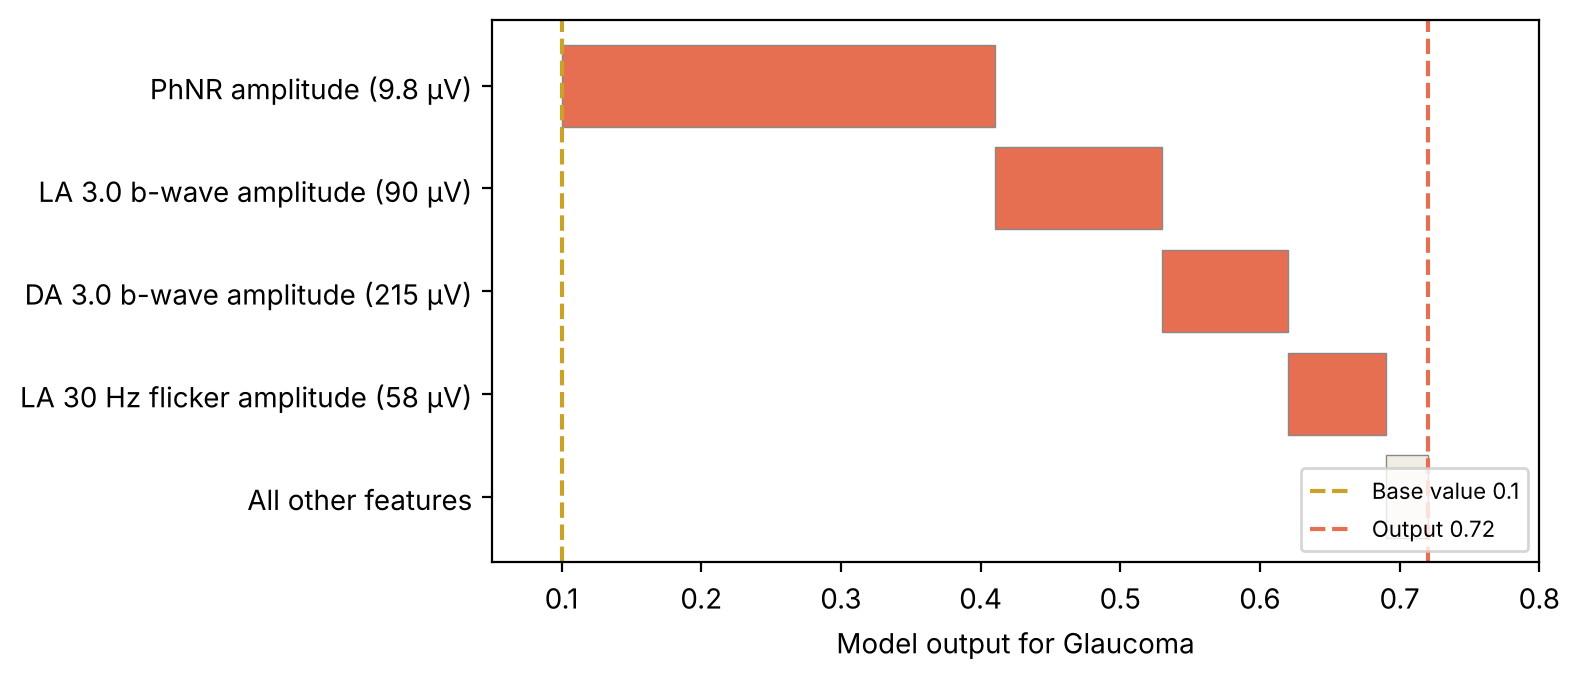

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 3.5))
start = base
for i, (name, v) in enumerate(zip(shap['Feature (measured value)'], shap['SHAP value'])):
    colour = '#f1ede4' if name == 'All other features' else '#e76f51'
    ax.barh(i, v, left=start, color=colour, edgecolor='#888888', linewidth=0.5)
    start += v
ax.axvline(base, color='#c9a227', linestyle='--', label=f'Base value {base}')
ax.axvline(start, color='#e76f51', linestyle='--', label=f'Output {start:.2f}')
ax.set_xlim(0.05, 0.80)
ax.set_yticks(range(len(shap)), shap['Feature (measured value)'])
ax.invert_yaxis()
ax.set_xlabel('Model output for Glaucoma')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()